In [1]:
import os,warnings
import joblib 
import random
import json
import datetime
import tensorflow   as tf
import numpy as np
import keras

from tensorflow.keras.optimizers    import Adam
from tensorflow.keras.callbacks     import EarlyStopping, ReduceLROnPlateau
from tqdm                           import tqdm
from preProcessingData              import PreProcessData
from utility.logger                 import aiLogger
from utility.matpilotDraw           import MatPlot
from tKanModel                          import vaeTKAN
import matplotlib.pyplot            as plt
from keras.models                   import load_model


os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # disabling gpu usage because my cuda is corrupted, needs to be fixed. 

2024-10-03 00:22:48.397118: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:485] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2024-10-03 00:22:48.414673: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:8454] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2024-10-03 00:22:48.419637: E external/local_xla/xla/stream_executor/cuda/cuda_blas.cc:1452] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-03 00:22:48.432347: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-10-03 00:22:49.166708: W tensorflow/compiler/tf2

In [2]:
with open('model/modelConfig.json', 'r') as configFile:
        config = json.load(configFile)
kanConfig = config["kan"]  

# ---------------------------------    
# Reactor, Separator,Stripper
# ---------------------------------
component  = kanConfig["component"]
modelName  = "kan"


os.environ['CUDA_VISIBLE_DEVICES'] = '1'
# strategy = tf.distribute.MirroredStrategy()


np.random.seed(1)
random.seed(1)
# ---------------------------------
# Pre processing data
# ---------------------------------
preData                         = PreProcessData()
rawData                         = preData.loadCriticalData()                                            # Load the data from critical file
addedVariablesData              = preData.additionEfficiencyVar(rawData)                                # Add some additional efficiency variable
normalizedAllData               = preData.normalizeBuilinFunction(addedVariablesData)                   # Normalize the all data
normalizedHealthy,healthyPos    = preData.getHealthyState(normalizedAllData)       # Load the healthy state
trajectory                      = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.beauEfficiencyCr1 + preData.addEfficiencyCr1)         # Extract the trajectory


listOfData                      = []
for vlTraj in trajectory.values():
        listOfData = listOfData + vlTraj

# clearnData              = preData.cleanData(rawData[preData.crusher1Value])                     # Clean the data by using moving average
# norData                 = preData.normalizeBuilinFunction(clearnData[preData.crusher1Value])    # Normalize the data

# ---------------------------
# All data
# --------------------------
# seqData,_     = preData.splitAllDataIntoSequences(listOfData)
# print(f"The size of the data: {seqData.shape}")

# ---------------------------
# Single sample
# ---------------------------
singleTraject   = trajectory["Falta de aceite hidráulico"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap'])

trajectory.keys()

Process:23164||2024-10-03 00:22:54,025-INFO [preProcessingData.py:loadCriticalData():220]:Loading critical MOF data from files ...
Process:23164||2024-10-03 00:22:54,446-INFO [preProcessingData.py:loadCriticalData():226]:Finish loading data from files ...


29


Process:23164||2024-10-03 00:22:54,854-INFO [preProcessingData.py:getHealthyState():470]:Getting critical trajectories ...


dict_keys(['Válvula defectuosa', 'Falta de aceite hidráulico', 'Lubricación  deficiente', 'Temperatura fuera de rango', 'Bomba hidráulica con fuga', 'Fuga de aceite', 'Falla sistema de hidroset-poste', 'Mandibulas o revestimiento suelto'])

I0000 00:00:1727907776.175094   23164 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727907776.215613   23164 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727907776.220464   23164 cuda_executor.cc:1015] successful NUMA node read from SysFS had negative value (-1), but there must be at least one NUMA node, so returning NUMA node zero. See more at https://github.com/torvalds/linux/blob/v6.0/Documentation/ABI/testing/sysfs-bus-pci#L344-L355
I0000 00:00:1727907776.225382   23164 cuda_executor.cc:1015] successful NUMA node read from SysFS ha

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 128, 17)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan (TKAN)         │ (None, 128, 40)   │     10,536 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan_1 (TKAN)       │ (None, 10)        │     46,244 │ tkan[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 56,824 (221.97 KB)

 Trainable params: 56,254 (219.74 KB)

 Non-trainable params: 570 (2.23 KB)

... (5 outputs left out)

 Non-trainable params: 120 (480.00 B)

None
Epoch 1/10
---------------------------------
(None, 128, 17)
---------------------------------
(None, 128, 17)


I0000 00:00:1727907794.586848   23241 service.cc:146] XLA service 0x1362d7b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1727907794.586877   23241 service.cc:154]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Ti, Compute Capability 8.9
2024-10-03 00:23:15.247697: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2024-10-03 00:23:17.689935: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:531] Loaded cuDNN version 8907
I0000 00:00:1727907812.788324   23241 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


46/46 ━━━━━━━━━━━━━━━━━━━━ 61s 569ms/step - kl_loss: 0.0325 - loss: 2.7326 - reconstruction_loss: 0.9000
Epoch 2/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 159ms/step - kl_loss: 9.2721e-06 - loss: 0.1219 - reconstruction_loss: 0.0406
Epoch 3/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 158ms/step - kl_loss: 1.9123e-06 - loss: 0.0994 - reconstruction_loss: 0.0331
Epoch 4/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 156ms/step - kl_loss: 5.5306e-07 - loss: 0.1047 - reconstruction_loss: 0.0349
Epoch 5/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 157ms/step - kl_loss: 4.2299e-07 - loss: 0.0985 - reconstruction_loss: 0.0328
Epoch 6/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 159ms/step - kl_loss: 3.4138e-07 - loss: 0.1015 - reconstruction_loss: 0.0338
Epoch 7/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 161ms/step - kl_loss: 2.9899e-07 - loss: 0.0980 - reconstruction_loss: 0.0327
Epoch 8/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 159ms/step - kl_loss: 2.8858e-07 - loss: 0.0983 - reconstruction_loss: 0.0328
Epoch 9/10
46/46 ━━━━━━━━━━━━━━━━━━━━ 7s 158ms/step - kl_loss:

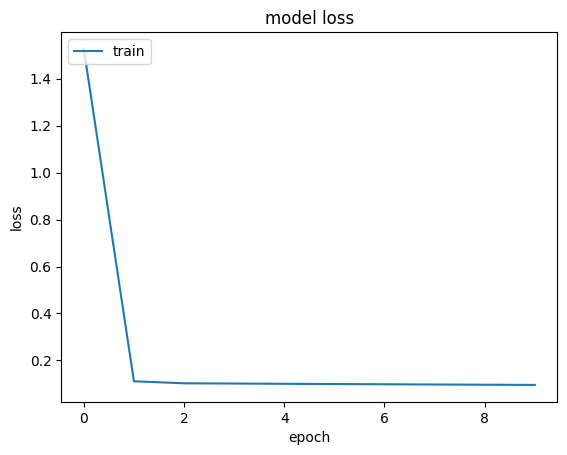

In [3]:
# ---------------------------------
# Model
# ---------------------------------
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
aiModel             = vaeTKAN(config=kanConfig)        

aiModel.compile(optimizer= Adam())
early_stop_loss     = 'loss'
early_stop_callback = EarlyStopping(monitor=early_stop_loss, min_delta = 1e-3, patience=5) 

history = aiModel.fit(
                        x           =   seqData,
                        y           =   seqData,
                        batch_size  =   kanConfig['batchSize'],
                        epochs      =   kanConfig['nEpoch'],
                        shuffle     =   True,
                        callbacks   =   [early_stop_callback],
                        verbose     =   1,
                        )


# ---------------------------------
# Save results
# ---------------------------------
plt.plot(history.history["loss"])
# plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train"],loc ="upper left")

# val_loss = history.history["val_loss"][-1]
# plt.savefig(kanConfig['dir'] + "/" +  "loss" + str(val_loss) + ".png")

(2937, 128, 17)


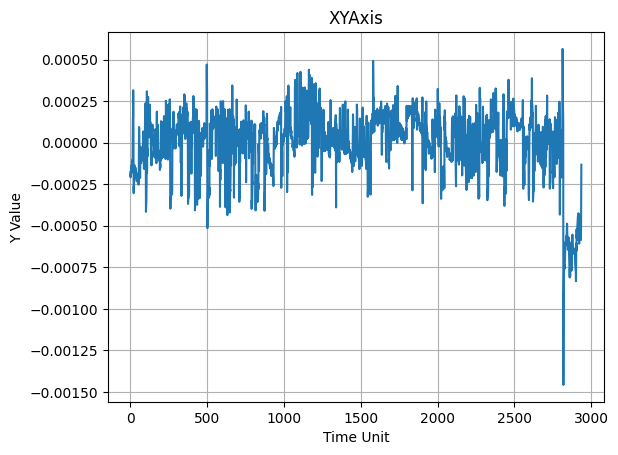

In [4]:
plot = MatPlot()

# ======================================
#  PREPROCESS THE DATA
# --------------------------------------
singleTraject   = trajectory["Falta de aceite hidráulico"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap']) # Split data into each sequence

print(seqData.shape)
zLatent,_     = aiModel(seqData)
# print(zLatent.shape)
hi  = tf.reduce_mean(zLatent, axis=1)

plot.draw1D(hi)